# 5. Serving and latency

The model scored one transaction at a time by a service that keeps a time-sorted neighbour index. Numbers come from one machine replaying historical data; they are not a production claim, and the 100 ms budget is an illustrative assumption.

In [1]:
%matplotlib inline
from pipeline.notebook_support import *
import pandas as pd
import numpy as np
pd.set_option('display.width', 160)
import json
lat = load_results('latency.csv')
meta = json.loads((out_dir() / 'latency_meta.json').read_text())
print('FIXTURE RESULTS - not findings' if meta['fixture'] else 'real data')
print('hardware:', meta['hardware'])
print('parity with the offline scores:', meta['parity'])

real data
hardware: {'platform': 'Windows-11-10.0.26300-SP0', 'processor': 'AMD64 Family 25 Model 68 Stepping 1, AuthenticAMD', 'cpu_count': 16, 'python': '3.14.7', 'torch': '2.14.1+cu130', 'gpu': 'NVIDIA GeForce RTX 3070 Ti Laptop GPU'}
parity with the offline scores: {'checked': True, 'max_abs_diff': 0.0, 'n_rows': 200, 'reason': ''}


In [2]:
cols = ['model', 'device', 'mode', 'batch_size', 'concurrency', 'p50_ms', 'p95_ms', 'p99_ms', 'throughput_rps', 'p99_within_budget']
lat[cols].round(2)

,model,device,mode,batch_size,concurrency,p50_ms,p95_ms,p99_ms,throughput_rps,p99_within_budget
0,gnn,cpu,inprocess,1,1,18.88,22.58,26.44,53.01,True
1,gnn,cpu,inprocess,8,1,25.51,28.86,30.27,317.02,True
2,gnn,cpu,inprocess,32,1,46.35,50.27,69.96,700.93,True
3,gnn,cpu,inprocess,128,1,140.13,158.32,161.91,907.76,False
4,gnn,cuda,inprocess,1,1,25.78,33.83,39.66,37.65,True
5,gnn,cuda,inprocess,8,1,32.80,41.95,49.63,237.83,True
6,gnn,cuda,inprocess,32,1,47.32,54.91,61.37,663.43,True
7,gnn,cuda,inprocess,128,1,119.54,127.59,128.86,1076.84,False
8,gnn,cpu,http,1,1,21.28,29.05,37.28,45.52,True
9,gnn,cpu,http,32,1,55.83,64.15,67.40,561.06,True


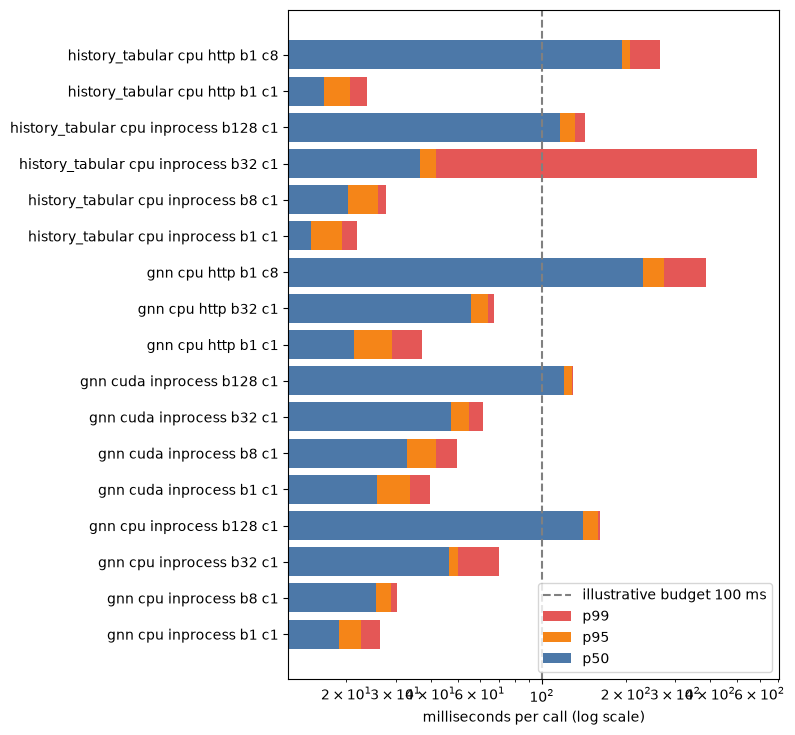

In [3]:
plot_latency(lat, meta['budget_ms']);

## Where the time goes (batch size 1)

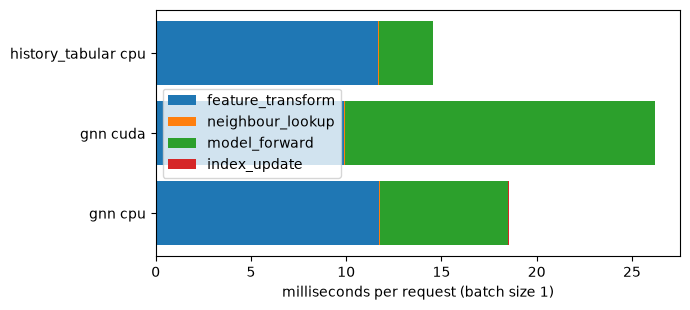

In [4]:
plot_breakdown(lat);

## Stock sampler versus the custom index

The `stock_neighbor_loader` row is the cost of sampling the neighbourhood alone with PyG's loader built per request; compare it with the `neighbour_lookup` share above.

In [5]:
lat[lat['mode'] == 'lookup_only'][['model', 'p50_ms', 'p95_ms', 'p99_ms']].round(2)

,model,p50_ms,p95_ms,p99_ms
17,stock_neighbor_loader,322.82,385.15,467.11


Index size and the concurrency caveat: the metadata printed above lists the indexed transactions and the serialised index size. Scoring is serialised by one lock, so extra clients do not add throughput; the multi-client row shows the queueing cost.